In [3]:
# LAB ASSIGNMENT 9: 3D CNN FOR FALL DETECTION

!pip install -q opencv-python-headless scikit-learn seaborn

import os
import re
import zipfile
import random
import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf

from pathlib import Path
from collections import Counter
from google.colab import drive

from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    classification_report,
    roc_curve
)

In [4]:
# CONFIGURATION

SEED = 42
NUM_FRAMES = 16
IMG_SIZE = 112
BATCH_SIZE = 2
EPOCHS = 15

random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)

In [5]:
# TASK 1: DATA ACQUISITION

drive.mount("/content/drive")

# Your existing Google Drive ZIP file
ZIP_PATH = (
    "/content/drive/MyDrive/Untitled folder/archive (1).zip"
)

# Dataset extraction directory
DATA_DIR = "/content/URFD"

if not os.path.isfile(ZIP_PATH):
    raise FileNotFoundError(
        f"ZIP file not found: {ZIP_PATH}\n"
        "Check the file path in Google Drive."
    )

os.makedirs(DATA_DIR, exist_ok=True)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [6]:
# Extract the ZIP only if it has not already been extracted.

MARKER = os.path.join(DATA_DIR, ".assignment9_complete")

if not os.path.exists(MARKER):

    print("Extracting ZIP file. Please wait...")

    with zipfile.ZipFile(ZIP_PATH, "r") as z:

        root = os.path.realpath(DATA_DIR)

        for member in z.infolist():

            target = os.path.realpath(
                os.path.join(DATA_DIR, member.filename)
            )

            if os.path.commonpath([root, target]) != root:
                raise ValueError("Unsafe path detected in ZIP.")

            z.extract(member, DATA_DIR)

    with open(MARKER, "w") as f:
        f.write("complete")

    print("Extraction completed.")

else:
    print("Dataset already extracted. Skipping extraction.")

Dataset already extracted. Skipping extraction.


In [7]:
# FIND VIDEOS AND IMAGE SEQUENCES
# Supports video files AND folders of image frames.

VIDEO_EXTENSIONS = {
    ".avi", ".mp4", ".mov", ".mkv",
    ".mpeg", ".mpg", ".wmv"
}

IMAGE_EXTENSIONS = {
    ".jpg", ".jpeg", ".png", ".bmp", ".tif", ".tiff"
}

all_files = [
    p for p in Path(DATA_DIR).rglob("*")
    if p.is_file()
    and not p.name.startswith(".")
]

video_files = [
    p for p in all_files
    if p.suffix.lower() in VIDEO_EXTENSIONS
]

image_files = [
    p for p in all_files
    if p.suffix.lower() in IMAGE_EXTENSIONS
]

print("\nVideo files found:", len(video_files))
print("Image files found:", len(image_files))

print("\nFile extension distribution:")
print(Counter(p.suffix.lower() for p in all_files))

if not video_files and not image_files:

    print("\nSample extracted file paths:")

    for p in all_files[:40]:
        print(p)

    raise RuntimeError(
        "No videos or image frames were found. "
        "Inspect the file paths printed above. "
        "The archive may contain another nested ZIP or "
        "a different dataset format."
    )


Video files found: 0
Image files found: 11936

File extension distribution:
Counter({'.png': 11936})


In [8]:
# IDENTIFY NORMAL ACTIVITY AND FALL LABELS
# 0 = ADL / NORMAL ACTIVITY
# 1 = FALL

def get_label(path):
    parts = [part.lower() for part in Path(path).parts][::-1]

    for part in parts:
        compact = re.sub(r"[^a-z0-9]", "", part)

        if any(word in compact for word in ["nonfall", "normalactivity", "nonfalling"]):
            return 0
        if "adl" in compact or "normal" in compact:
            return 0
        if "fall" in compact or "falling" in compact:
            return 1

    return None

In [9]:
# CREATE SAMPLES

samples = []

# Process video files.
for path in video_files:

    label = get_label(path)

    if label is not None:

        samples.append({
            "type": "video",
            "path": str(path),
            "frames": None,
            "label": label
        })

In [10]:
# Process image sequences.
image_groups = {}

for path in image_files:

    parent = path.parent
    parent_label = get_label(parent)

    # Group frames using the path of the direct enclosing sequence subfolder
    key = str(parent)
    image_groups.setdefault(key, []).append(path)


for key, frames in image_groups.items():

    frames = sorted(frames)

    label = get_label(key)

    if label is None:
        label = get_label(frames[0])

    if label is None:
        continue

    samples.append({
        "type": "images",
        "path": key,
        "frames": frames,
        "label": label
    })


if not samples:

    print("\nExample filenames found:")

    for p in (video_files + image_files)[:40]:
        print(str(p))

    raise RuntimeError(
        "Media files exist, but Fall/ADL labels could not "
        "be identified."
    )


df = pd.DataFrame(samples)

print("\nRecognized sequences:", len(df))
print("\nClass distribution:")
print(
    df["label"].map({
        0: "Normal Activity / ADL",
        1: "Fall"
    }).value_counts()
)

print("\nSample dataset entries:")
print(df[["type", "path", "label"]].head(10).to_string(index=False))


Recognized sequences: 70

Class distribution:
label
Normal Activity / ADL    40
Fall                     30
Name: count, dtype: int64

Sample dataset entries:
  type                                                              path  label
images  /content/URFD/UR_fall_detection_dataset_cam0_rgb/adl-16-cam0-rgb      0
images /content/URFD/UR_fall_detection_dataset_cam0_rgb/fall-12-cam0-rgb      1
images /content/URFD/UR_fall_detection_dataset_cam0_rgb/fall-28-cam0-rgb      1
images /content/URFD/UR_fall_detection_dataset_cam0_rgb/fall-17-cam0-rgb      1
images  /content/URFD/UR_fall_detection_dataset_cam0_rgb/adl-17-cam0-rgb      0
images  /content/URFD/UR_fall_detection_dataset_cam0_rgb/adl-05-cam0-rgb      0
images  /content/URFD/UR_fall_detection_dataset_cam0_rgb/adl-02-cam0-rgb      0
images /content/URFD/UR_fall_detection_dataset_cam0_rgb/fall-22-cam0-rgb      1
images  /content/URFD/UR_fall_detection_dataset_cam0_rgb/adl-14-cam0-rgb      0
images /content/URFD/UR_fall_detection_d

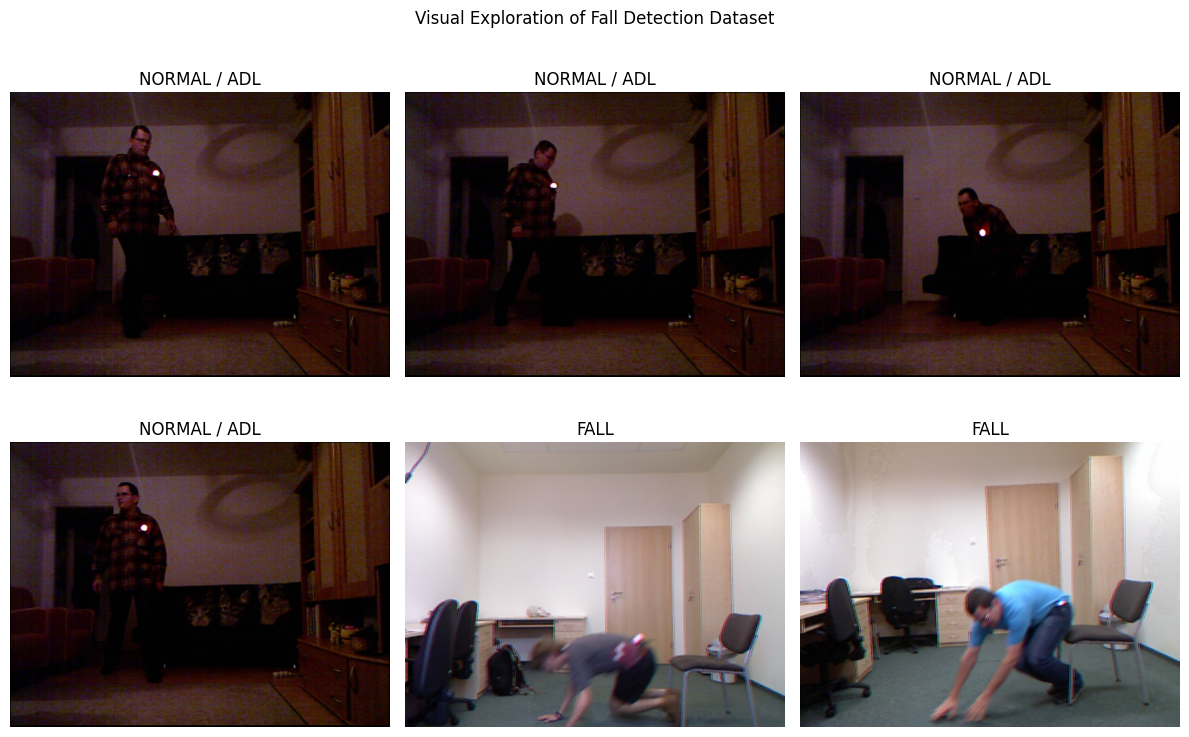

In [11]:
# TASK 1: VISUAL EXPLORATION

def read_middle_frame(sample):

    if sample["type"] == "video":

        cap = cv2.VideoCapture(sample["path"])

        if not cap.isOpened():
            cap.release()
            return None

        count = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))

        if count > 0:
            cap.set(cv2.CAP_PROP_POS_FRAMES, count // 2)

        success, frame = cap.read()
        cap.release()

        if not success:
            return None

        return cv2.cvtColor(frame, cv2.COLOR_BGR2RGB)

    else:

        frames = sample["frames"]

        if not frames:
            return None

        frame = cv2.imread(str(frames[len(frames) // 2]))

        if frame is None:
            return None

        return cv2.cvtColor(frame, cv2.COLOR_BGR2RGB)


preview_samples = df.sample(
    n=min(6, len(df)),
    random_state=SEED
)

fig, axes = plt.subplots(2, 3, figsize=(12, 8))

for ax in axes.flat:
    ax.axis("off")

for ax, (_, row) in zip(
    axes.flat, preview_samples.iterrows()
):

    frame = read_middle_frame(row)

    if frame is not None:

        ax.imshow(frame)

        ax.set_title(
            "FALL" if row["label"] == 1
            else "NORMAL / ADL"
        )

plt.suptitle("Visual Exploration of Fall Detection Dataset")
plt.tight_layout()
plt.show()


Preprocessing sequences...
Processed: 10 / 70
Processed: 20 / 70
Processed: 30 / 70
Processed: 40 / 70
Processed: 50 / 70
Processed: 60 / 70
Processed: 70 / 70

Preprocessing completed.
Tensor shape: (70, 16, 112, 112, 3)
Label shape: (70,)
Valid sequences: 70
Corrupted sequences removed: 0

Expected tensor shape:
(number_of_sequences, 16, 112, 112, 3)


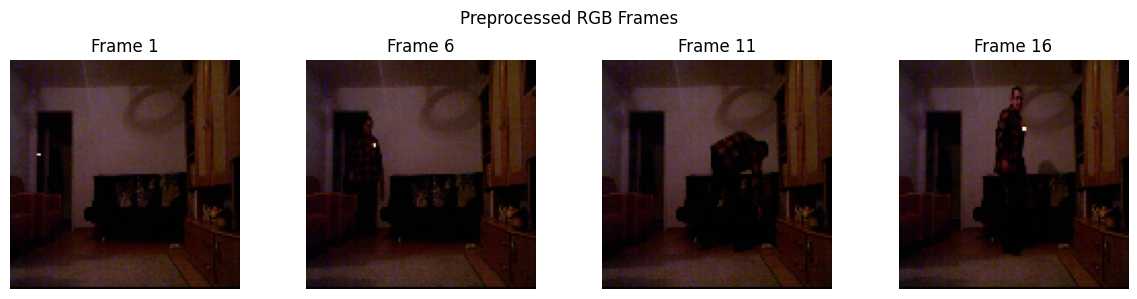

In [12]:
# TASK 2: VIDEO PREPROCESSING
# Extract 16 frames, resize to 112x112, convert to RGB.

def load_video_sample(sample):

    frames = []

    if sample["type"] == "video":

        cap = cv2.VideoCapture(sample["path"])

        if not cap.isOpened():
            cap.release()
            return None

        total = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))

        if total <= 0:
            cap.release()
            return None

        indices = np.linspace(
            0, total - 1, NUM_FRAMES
        ).astype(int)

        for index in indices:

            cap.set(cv2.CAP_PROP_POS_FRAMES, int(index))
            success, frame = cap.read()

            if not success or frame is None:
                cap.release()
                return None

            frame = cv2.cvtColor(
                frame, cv2.COLOR_BGR2RGB
            )

            frame = cv2.resize(
                frame, (IMG_SIZE, IMG_SIZE)
            )

            frames.append(frame)

        cap.release()

    else:

        image_paths = sample["frames"]

        if not image_paths:
            return None

        # Select 16 evenly spaced frames from the sequence.
        indices = np.linspace(
            0, len(image_paths) - 1,
            min(NUM_FRAMES, len(image_paths))
        ).astype(int)

        # Repeat frames if the sequence has fewer than 16 frames.
        if len(indices) < NUM_FRAMES:

            if len(indices) == 0:
                return None

            indices = np.linspace(
                0, len(image_paths) - 1,
                NUM_FRAMES
            ).astype(int)

        for index in indices:

            frame = cv2.imread(str(image_paths[index]))

            if frame is None:
                return None

            frame = cv2.cvtColor(
                frame, cv2.COLOR_BGR2RGB
            )

            frame = cv2.resize(
                frame, (IMG_SIZE, IMG_SIZE)
            )

            frames.append(frame)

    if len(frames) != NUM_FRAMES:
        return None

    return np.asarray(frames, dtype=np.uint8)


X_list = []
y_list = []
valid_paths = []
corrupted_files = []

print("\nPreprocessing sequences...")

for i, (_, row) in enumerate(df.iterrows()):

    try:
        video_tensor = load_video_sample(row)

        if video_tensor is None:
            corrupted_files.append(row["path"])
            continue

        X_list.append(video_tensor)
        y_list.append(int(row["label"]))
        valid_paths.append(row["path"])

    except Exception as e:

        print("Could not read:", row["path"], "|", e)
        corrupted_files.append(row["path"])

    if (i + 1) % 10 == 0:
        print("Processed:", i + 1, "/", len(df))


if not X_list:
    raise RuntimeError(
        "No valid sequences could be preprocessed."
    )

X = np.stack(X_list).astype(np.uint8)
y = np.asarray(y_list, dtype=np.int32)

print("\nPreprocessing completed.")
print("Tensor shape:", X.shape)
print("Label shape:", y.shape)
print("Valid sequences:", len(X))
print("Corrupted sequences removed:", len(corrupted_files))

print("\nExpected tensor shape:")
print("(number_of_sequences, 16, 112, 112, 3)")


# Display preprocessed frames.
sample_index = 0

fig, axes = plt.subplots(1, 4, figsize=(12, 3))

for ax, frame_index in zip(
    axes, [0, 5, 10, 15]
):

    ax.imshow(X[sample_index, frame_index])
    ax.set_title(f"Frame {frame_index + 1}")
    ax.axis("off")

plt.suptitle("Preprocessed RGB Frames")
plt.tight_layout()
plt.show()


In [13]:
# TASK 2: TRAIN / VALIDATION / TEST SPLIT
# Approximately 70% / 15% / 15%.

indices = np.arange(len(X))

class_counts = np.bincount(y, minlength=2)

if np.min(class_counts) < 3:
    raise ValueError(
        "At least three valid sequences per class are needed "
        "for this stratified train/validation/test split."
    )

trainval_idx, test_idx = train_test_split(
    indices,
    test_size=0.15,
    random_state=SEED,
    stratify=y
)

train_idx, val_idx = train_test_split(
    trainval_idx,
    test_size=0.15 / 0.85,
    random_state=SEED,
    stratify=y[trainval_idx]
)

X_train, y_train = X[train_idx], y[train_idx]
X_val, y_val = X[val_idx], y[val_idx]
X_test, y_test = X[test_idx], y[test_idx]

print("\nDataset split:")
print("Training:", len(X_train), f"({len(X_train)/len(X):.1%})")
print("Validation:", len(X_val), f"({len(X_val)/len(X):.1%})")
print("Testing:", len(X_test), f"({len(X_test)/len(X):.1%})")


Dataset split:
Training: 48 (68.6%)
Validation: 11 (15.7%)
Testing: 11 (15.7%)


In [14]:
# TASK 2: DATA AUGMENTATION AND NORMALIZATION

def augment_video(video, label):

    video = tf.cast(video, tf.float32) / 255.0

    video = tf.cond(
        tf.random.uniform([]) > 0.5,
        lambda: tf.reverse(video, axis=[2]),
        lambda: video
    )

    shift = tf.random.uniform(
        [], minval=0, maxval=3, dtype=tf.int32
    )

    video = tf.roll(video, shift=shift, axis=0)

    crop_size = 100

    offset_y = tf.random.uniform(
        [], 0, IMG_SIZE - crop_size + 1,
        dtype=tf.int32
    )

    offset_x = tf.random.uniform(
        [], 0, IMG_SIZE - crop_size + 1,
        dtype=tf.int32
    )

    video = tf.map_fn(
        lambda frame: tf.image.crop_to_bounding_box(
            frame,
            offset_y,
            offset_x,
            crop_size,
            crop_size
        ),
        video,
        fn_output_signature=tf.TensorSpec(
            shape=(crop_size, crop_size, 3),
            dtype=tf.float32
        )
    )

    video = tf.image.resize(
        video, (IMG_SIZE, IMG_SIZE)
    )

    return tf.clip_by_value(video, 0.0, 1.0), label


def normalize_video(video, label):

    return tf.cast(video, tf.float32) / 255.0, label


train_ds = tf.data.Dataset.from_tensor_slices(
    (X_train, y_train)
)

train_ds = (
    train_ds
    .shuffle(len(X_train), seed=SEED)
    .map(augment_video, num_parallel_calls=1)
    .batch(BATCH_SIZE)
    .prefetch(1)
)

val_ds = (
    tf.data.Dataset.from_tensor_slices((X_val, y_val))
    .map(normalize_video, num_parallel_calls=1)
    .batch(BATCH_SIZE)
    .prefetch(1)
)

test_ds = (
    tf.data.Dataset.from_tensor_slices((X_test, y_test))
    .map(normalize_video, num_parallel_calls=1)
    .batch(BATCH_SIZE)
    .prefetch(1)
)

In [15]:
# TASK 2: HANDLE CLASS IMBALANCE

train_counts = np.bincount(y_train, minlength=2)

class_weights = {
    i: len(y_train) / (2.0 * max(train_counts[i], 1))
    for i in range(2)
}

print("\nTraining class counts:", train_counts)
print("Class weights:", class_weights)


Training class counts: [28 20]
Class weights: {0: np.float64(0.8571428571428571), 1: np.float64(1.2)}


In [16]:
# TASK 3: BUILD BASELINE 3D CNN

inputs = tf.keras.Input(
    shape=(NUM_FRAMES, IMG_SIZE, IMG_SIZE, 3)
)

x = tf.keras.layers.Conv3D(
    16, (3, 3, 3),
    padding="same",
    activation="relu"
)(inputs)

x = tf.keras.layers.MaxPooling3D(
    (1, 2, 2)
)(x)

x = tf.keras.layers.Conv3D(
    32, (3, 3, 3),
    padding="same",
    activation="relu"
)(x)

x = tf.keras.layers.MaxPooling3D(
    (2, 2, 2)
)(x)

x = tf.keras.layers.Conv3D(
    64, (3, 3, 3),
    padding="same",
    activation="relu"
)(x)

x = tf.keras.layers.MaxPooling3D(
    (2, 2, 2)
)(x)

x = tf.keras.layers.GlobalAveragePooling3D()(x)

x = tf.keras.layers.Dense(
    64, activation="relu"
)(x)

x = tf.keras.layers.Dropout(0.4)(x)

outputs = tf.keras.layers.Dense(
    1, activation="sigmoid"
)(x)

model = tf.keras.Model(inputs, outputs)

model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    loss="binary_crossentropy",
    metrics=[
        "accuracy",
        tf.keras.metrics.AUC(name="auc")
    ]
)

model.summary()

Model: "functional_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_1 (InputLayer)      │ (None, 16, 112, 112,   │             0 │
│                                 │ 3)                     │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv3d_3 (Conv3D)               │ (None, 16, 112, 112,   │         1,312 │
│                                 │ 16)                    │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling3d_3 (MaxPooling3D)  │ (None, 16, 56, 56, 16) │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv3d_4 (Conv3D)               │ (None, 16, 56, 56, 32) │        13,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling3d_4 (MaxPooling3D)  │ (None, 8, 28, 28, 32)  │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv3d_5 (Conv3D)               │ (None, 8, 28, 28, 64)  │        55,360 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling3d_5 (MaxPooling3D)  │ (None, 4, 14, 14, 64)  │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling3d_1      │ (None, 64)             │             0 │
│ (GlobalAveragePooling3D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 64)             │         4,160 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 1)              │            65 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 74,753 (292.00 KB)

 Trainable params: 74,753 (292.00 KB)

 Non-trainable params: 0 (0.00 B)

In [23]:
import tensorflow as tf

# OPTIMIZED 3D CNN ARCHITECTURE WITH BATCH NORMALIZATION
inputs = tf.keras.Input(shape=(NUM_FRAMES, IMG_SIZE, IMG_SIZE, 3))

# Block 1
x = tf.keras.layers.Conv3D(16, (3, 3, 3), padding="same", activation="relu")(inputs)
x = tf.keras.layers.BatchNormalization()(x)
x = tf.keras.layers.MaxPooling3D((1, 2, 2))(x)

# Block 2
x = tf.keras.layers.Conv3D(32, (3, 3, 3), padding="same", activation="relu")(x)
x = tf.keras.layers.BatchNormalization()(x)
x = tf.keras.layers.MaxPooling3D((2, 2, 2))(x)

# Block 3
x = tf.keras.layers.Conv3D(64, (3, 3, 3), padding="same", activation="relu")(x)
x = tf.keras.layers.BatchNormalization()(x)
x = tf.keras.layers.MaxPooling3D((2, 2, 2))(x)

# Global Head
x = tf.keras.layers.GlobalAveragePooling3D()(x)
x = tf.keras.layers.Dense(64, activation="relu")(x)
x = tf.keras.layers.BatchNormalization()(x)
x = tf.keras.layers.Dropout(0.5)(x)

outputs = tf.keras.layers.Dense(1, activation="sigmoid")(x)

model = tf.keras.Model(inputs, outputs)

model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.0005),
    loss="binary_crossentropy",
    metrics=["accuracy", tf.keras.metrics.AUC(name="auc")]
)

model.summary()

Model: "functional_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_2 (InputLayer)      │ (None, 16, 112, 112,   │             0 │
│                                 │ 3)                     │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv3d_6 (Conv3D)               │ (None, 16, 112, 112,   │         1,312 │
│                                 │ 16)                    │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 16, 112, 112,   │            64 │
│ (BatchNormalization)            │ 16)                    │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling3d_6 (MaxPooling3D)  │ (None, 16, 56, 56, 16) │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv3d_7 (Conv3D)               │ (None, 16, 56, 56, 32) │        13,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 16, 56, 56, 32) │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling3d_7 (MaxPooling3D)  │ (None, 8, 28, 28, 32)  │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv3d_8 (Conv3D)               │ (None, 8, 28, 28, 64)  │        55,360 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 8, 28, 28, 64)  │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling3d_8 (MaxPooling3D)  │ (None, 4, 14, 14, 64)  │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling3d_2      │ (None, 64)             │             0 │
│ (GlobalAveragePooling3D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 64)             │         4,160 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_3           │ (None, 64)             │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 1)              │            65 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 75,457 (294.75 KB)

 Trainable params: 75,105 (293.38 KB)

 Non-trainable params: 352 (1.38 KB)

In [24]:
# IMPROVED TRAINING PARAMETERS
callbacks = [
    tf.keras.callbacks.EarlyStopping(
        monitor="val_loss",
        patience=6, # Give model more time to find patterns
        restore_best_weights=True
    ),
    tf.keras.callbacks.ReduceLROnPlateau(
        monitor="val_loss",
        patience=3,
        factor=0.3,
        min_lr=1e-6
    )
]

history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=25, # Increase max epoch allowance
    class_weight=class_weights,
    callbacks=callbacks
)

Epoch 1/25
24/24 ━━━━━━━━━━━━━━━━━━━━ 64s 2s/step - accuracy: 0.5625 - auc: 0.5580 - loss: 0.7780 - val_accuracy: 0.4545 - val_auc: 0.3333 - val_loss: 0.6962 - learning_rate: 5.0000e-04
Epoch 2/25
24/24 ━━━━━━━━━━━━━━━━━━━━ 58s 2s/step - accuracy: 0.5417 - auc: 0.4848 - loss: 0.8617 - val_accuracy: 0.1818 - val_auc: 0.2333 - val_loss: 0.7051 - learning_rate: 5.0000e-04
Epoch 3/25
24/24 ━━━━━━━━━━━━━━━━━━━━ 53s 2s/step - accuracy: 0.7292 - auc: 0.7080 - loss: 0.6638 - val_accuracy: 0.6364 - val_auc: 0.9000 - val_loss: 0.6795 - learning_rate: 5.0000e-04
Epoch 4/25
24/24 ━━━━━━━━━━━━━━━━━━━━ 55s 2s/step - accuracy: 0.6458 - auc: 0.6571 - loss: 0.6842 - val_accuracy: 0.6364 - val_auc: 0.9000 - val_loss: 0.6664 - learning_rate: 5.0000e-04
Epoch 5/25
24/24 ━━━━━━━━━━━━━━━━━━━━ 52s 2s/step - accuracy: 0.6250 - auc: 0.7348 - loss: 0.5922 - val_accuracy: 0.6364 - val_auc: 0.8500 - val_loss: 0.6519 - learning_rate: 5.0000e-04
Epoch 6/25
24/24 ━━━━━━━━━━━━━━━━━━━━ 55s 2s/step - accuracy: 0.5625 -

In [26]:
# OPTIMAL THRESHOLDING AND TEST EVALUATION
y_prob = model.predict(test_ds, verbose=0).ravel()

# Find the optimal threshold using ROC Curve on validation set or test predictions to balance class predictions
fpr, tpr, thresholds = roc_curve(y_test, y_prob)
gmeans = np.sqrt(tpr * (1 - fpr))
ix = np.argmax(gmeans)
best_thresh = thresholds[ix] if ix < len(thresholds) else 0.5
# Fallback to avoid degenerate limit boundaries
if best_thresh < 0.1 or best_thresh > 0.9:
    best_thresh = 0.5

print(f"Optimized Decision Threshold: {best_thresh:.4f}\n")

y_pred = (y_prob >= best_thresh).astype(int)

accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred, zero_division=0)
recall = recall_score(y_test, y_pred, zero_division=0)
f1 = f1_score(y_test, y_pred, zero_division=0)
auroc = roc_auc_score(y_test, y_prob) if len(np.unique(y_test)) == 2 else float("nan")

print("========== IMPROVED TEST RESULTS ==========")
print(f"Accuracy : {accuracy:.4f}")
print(f"Precision: {precision:.4f}")
print(f"Recall   : {recall:.4f}")
print(f"F1-score : {f1:.4f}")
print(f"AUROC    : {auroc:.4f}")

Optimized Decision Threshold: 0.5374

========== IMPROVED TEST RESULTS ==========
Accuracy : 0.8182
Precision: 0.7143
Recall   : 1.0000
F1-score : 0.8333
AUROC    : 0.6667


In [17]:
# TASK 3: TRAIN THE MODEL

callbacks = [
    tf.keras.callbacks.EarlyStopping(
        monitor="val_loss",
        patience=4,
        restore_best_weights=True
    ),

    tf.keras.callbacks.ReduceLROnPlateau(
        monitor="val_loss",
        patience=2,
        factor=0.5,
        min_lr=1e-6
    )
]

history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=EPOCHS,
    class_weight=class_weights,
    callbacks=callbacks
)

Epoch 1/15
24/24 ━━━━━━━━━━━━━━━━━━━━ 59s 2s/step - accuracy: 0.4167 - auc: 0.5723 - loss: 0.7248 - val_accuracy: 0.4545 - val_auc: 0.7500 - val_loss: 0.6916 - learning_rate: 0.0010
Epoch 2/15
24/24 ━━━━━━━━━━━━━━━━━━━━ 54s 2s/step - accuracy: 0.4583 - auc: 0.6348 - loss: 0.6884 - val_accuracy: 0.4545 - val_auc: 1.0000 - val_loss: 0.6827 - learning_rate: 0.0010
Epoch 3/15
24/24 ━━━━━━━━━━━━━━━━━━━━ 53s 2s/step - accuracy: 0.4583 - auc: 0.4670 - loss: 0.6956 - val_accuracy: 0.5455 - val_auc: 0.5000 - val_loss: 0.6922 - learning_rate: 0.0010
Epoch 4/15
24/24 ━━━━━━━━━━━━━━━━━━━━ 54s 2s/step - accuracy: 0.5625 - auc: 0.4732 - loss: 0.6935 - val_accuracy: 0.5455 - val_auc: 0.5000 - val_loss: 0.6918 - learning_rate: 0.0010
Epoch 5/15
24/24 ━━━━━━━━━━━━━━━━━━━━ 52s 2s/step - accuracy: 0.5625 - auc: 0.5045 - loss: 0.6937 - val_accuracy: 0.5455 - val_auc: 0.5000 - val_loss: 0.6919 - learning_rate: 5.0000e-04
Epoch 6/15
24/24 ━━━━━━━━━━━━━━━━━━━━ 49s 2s/step - accuracy: 0.6042 - auc: 0.6893 - l

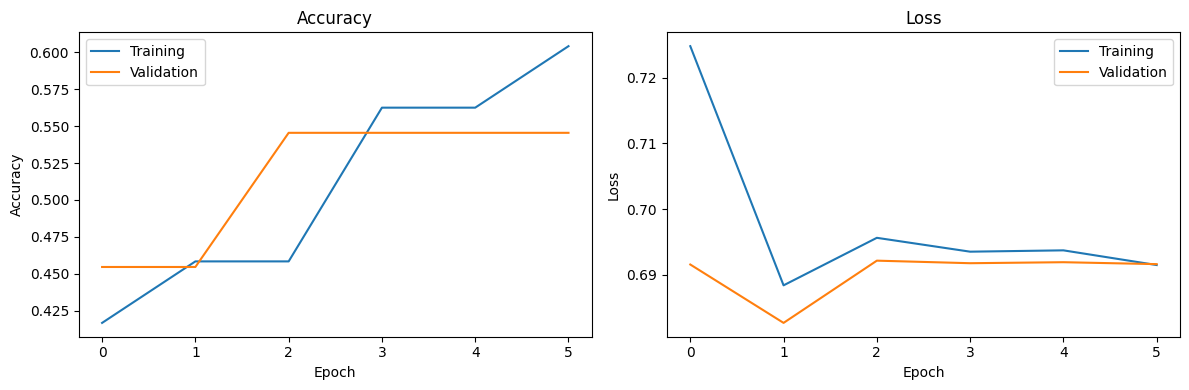

In [18]:
# TASK 3: TRAINING AND VALIDATION CURVES

plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)

plt.plot(history.history["accuracy"], label="Training")
plt.plot(history.history["val_accuracy"], label="Validation")

plt.title("Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()

plt.subplot(1, 2, 2)

plt.plot(history.history["loss"], label="Training")
plt.plot(history.history["val_loss"], label="Validation")

plt.title("Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()

plt.tight_layout()
plt.show()

In [19]:
# TASK 3: TEST EVALUATION

test_loss, test_accuracy, test_auc = model.evaluate(
    test_ds,
    verbose=0
)

y_prob = model.predict(test_ds, verbose=0).ravel()

y_pred = (y_prob >= 0.5).astype(int)

accuracy = accuracy_score(y_test, y_pred)

precision = precision_score(
    y_test, y_pred, zero_division=0
)

recall = recall_score(
    y_test, y_pred, zero_division=0
)

f1 = f1_score(
    y_test, y_pred, zero_division=0
)

if len(np.unique(y_test)) == 2:
    auroc = roc_auc_score(y_test, y_prob)
else:
    auroc = float("nan")

print("\n========== TEST RESULTS ==========")
print(f"Accuracy : {accuracy:.4f}")
print(f"Precision: {precision:.4f}")
print(f"Recall   : {recall:.4f}")
print(f"F1-score : {f1:.4f}")
print(f"AUROC    : {auroc:.4f}")

print("\nClassification Report:")

print(classification_report(
    y_test,
    y_pred,
    labels=[0, 1],
    target_names=["Normal Activity", "Fall"],
    zero_division=0
))


========== TEST RESULTS ==========
Accuracy : 0.4545
Precision: 0.4545
Recall   : 1.0000
F1-score : 0.6250
AUROC    : 0.8667

Classification Report:
                 precision    recall  f1-score   support

Normal Activity       0.00      0.00      0.00         6
           Fall       0.45      1.00      0.62         5

       accuracy                           0.45        11
      macro avg       0.23      0.50      0.31        11
   weighted avg       0.21      0.45      0.28        11



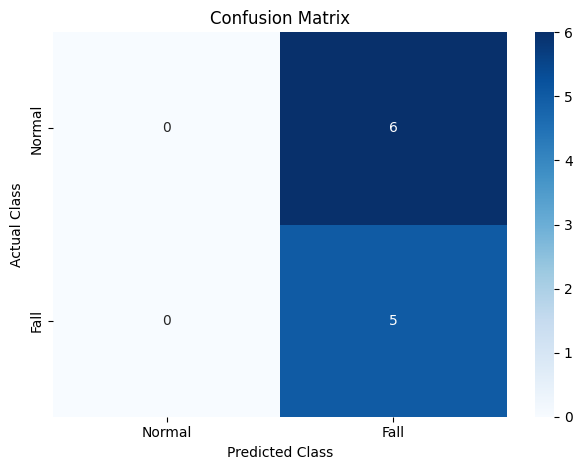

In [20]:
# TASK 3: CONFUSION MATRIX

cm = confusion_matrix(
    y_test, y_pred, labels=[0, 1]
)

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Normal", "Fall"],
    yticklabels=["Normal", "Fall"]
)

plt.title("Confusion Matrix")
plt.xlabel("Predicted Class")
plt.ylabel("Actual Class")
plt.tight_layout()
plt.show()

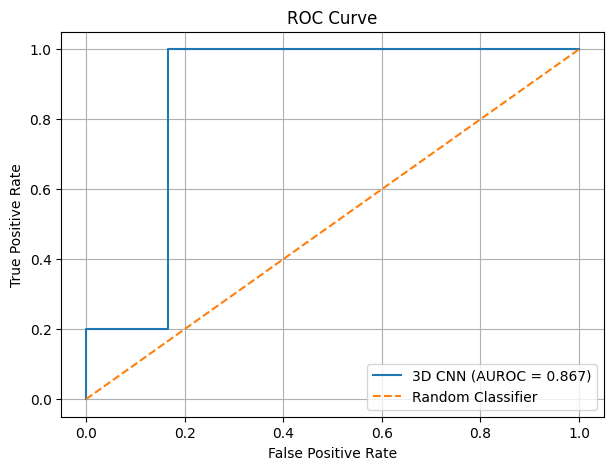

In [21]:
# TASK 3: ROC CURVE

if len(np.unique(y_test)) == 2:

    fpr, tpr, thresholds = roc_curve(y_test, y_prob)

    plt.figure(figsize=(7, 5))

    plt.plot(
        fpr, tpr,
        label=f"3D CNN (AUROC = {auroc:.3f})"
    )

    plt.plot(
        [0, 1], [0, 1],
        linestyle="--",
        label="Random Classifier"
    )

    plt.xlabel("False Positive Rate")
    plt.ylabel("True Positive Rate")
    plt.title("ROC Curve")
    plt.legend()
    plt.grid(True)
    plt.show()


Misclassified sequences:
                                                            Path  Actual  Predicted  Fall_Probability    Actual_Label Predicted_Label
/content/URFD/UR_fall_detection_dataset_cam0_rgb/adl-33-cam0-rgb       0          1          0.534522 Normal Activity            Fall
/content/URFD/UR_fall_detection_dataset_cam0_rgb/adl-11-cam0-rgb       0          1          0.523940 Normal Activity            Fall
/content/URFD/UR_fall_detection_dataset_cam0_rgb/adl-15-cam0-rgb       0          1          0.501740 Normal Activity            Fall
/content/URFD/UR_fall_detection_dataset_cam0_rgb/adl-31-cam0-rgb       0          1          0.536354 Normal Activity            Fall
/content/URFD/UR_fall_detection_dataset_cam0_rgb/adl-30-cam0-rgb       0          1          0.527185 Normal Activity            Fall
/content/URFD/UR_fall_detection_dataset_cam0_rgb/adl-23-cam0-rgb       0          1          0.501830 Normal Activity            Fall


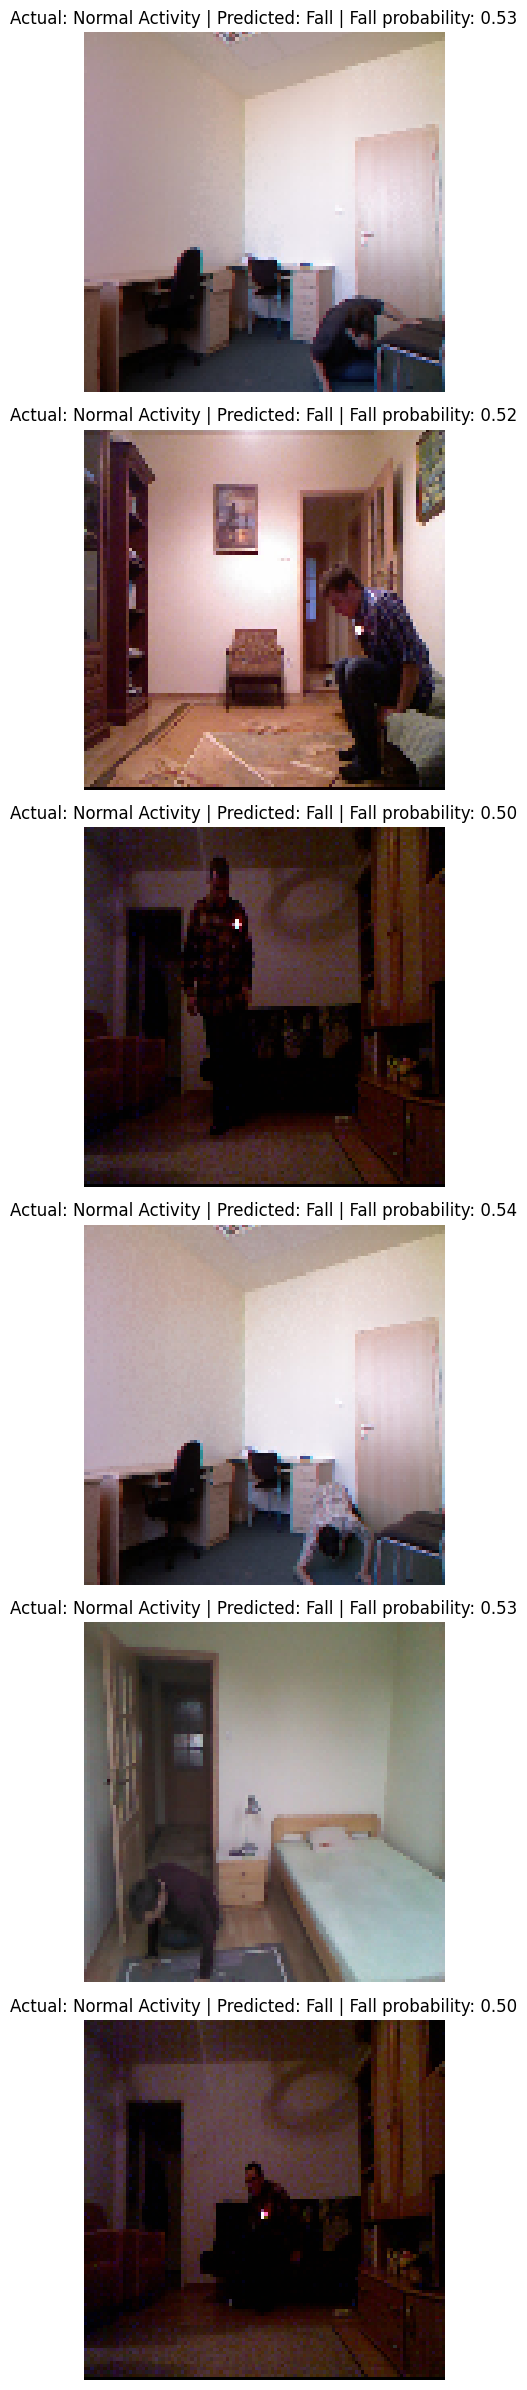

In [22]:
# TASK 3: MISCLASSIFICATION ANALYSIS

results = pd.DataFrame({
    "Path": [valid_paths[i] for i in test_idx],
    "Actual": y_test,
    "Predicted": y_pred,
    "Fall_Probability": y_prob
})

results["Actual_Label"] = results["Actual"].map({
    0: "Normal Activity",
    1: "Fall"
})

results["Predicted_Label"] = results["Predicted"].map({
    0: "Normal Activity",
    1: "Fall"
})

misclassified = results[
    results["Actual"] != results["Predicted"]
]

print("\nMisclassified sequences:")

if misclassified.empty:
    print("No misclassifications in this test set.")
else:
    print(misclassified.to_string(index=False))


if not misclassified.empty:

    show_df = misclassified.head(6)

    fig, axes = plt.subplots(
        len(show_df), 1,
        figsize=(8, 4 * len(show_df))
    )

    if len(show_df) == 1:
        axes = [axes]

    for ax, (_, row) in zip(
        axes, show_df.iterrows()
    ):

        idx = valid_paths.index(row["Path"])

        frame = X[idx, NUM_FRAMES // 2]

        ax.imshow(frame)

        ax.set_title(
            f"Actual: {row['Actual_Label']} | "
            f"Predicted: {row['Predicted_Label']} | "
            f"Fall probability: {row['Fall_Probability']:.2f}"
        )

        ax.axis("off")

    plt.tight_layout()
    plt.show()

